<a href="https://colab.research.google.com/github/Faiva-404/PemMes-Ganjil-2026/blob/main/JS10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Klasifikasi**

K-Neasrest Neighbors (KNN)

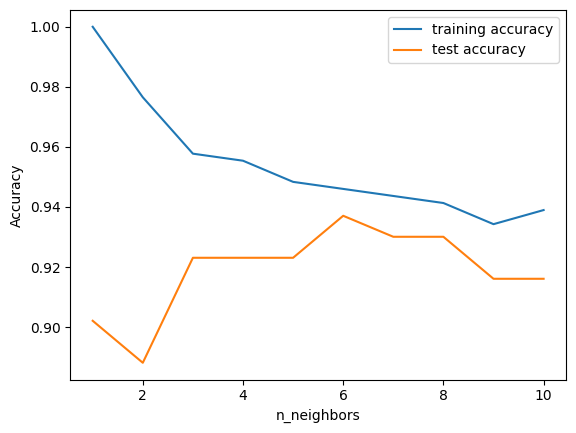

In [ ]:
# Introduction to Machine Learning
# Andreas C. Müller, Sarah Guido (2023)
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, stratify=cancer.target, random_state=66)
training_accuracy = []
test_accuracy = []

# try n_neighbors from 1 to 10
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
  # build the model
  clf = KNeighborsClassifier(n_neighbors=n_neighbors)
  clf.fit(X_train, y_train)
  # record training set accuracy
  training_accuracy.append(clf.score(X_train, y_train))
  # record generalization accuracy
  test_accuracy.append(clf.score(X_test, y_test))


plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.legend()



> Praktikum 1



In [ ]:
# Load data
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/Mesin/iris (2).csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Evaluasi Model Dengan R-squared (R2)

In [ ]:
#Langkah 2 - Eksplorasi Data
data.info()
data.describe()
data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


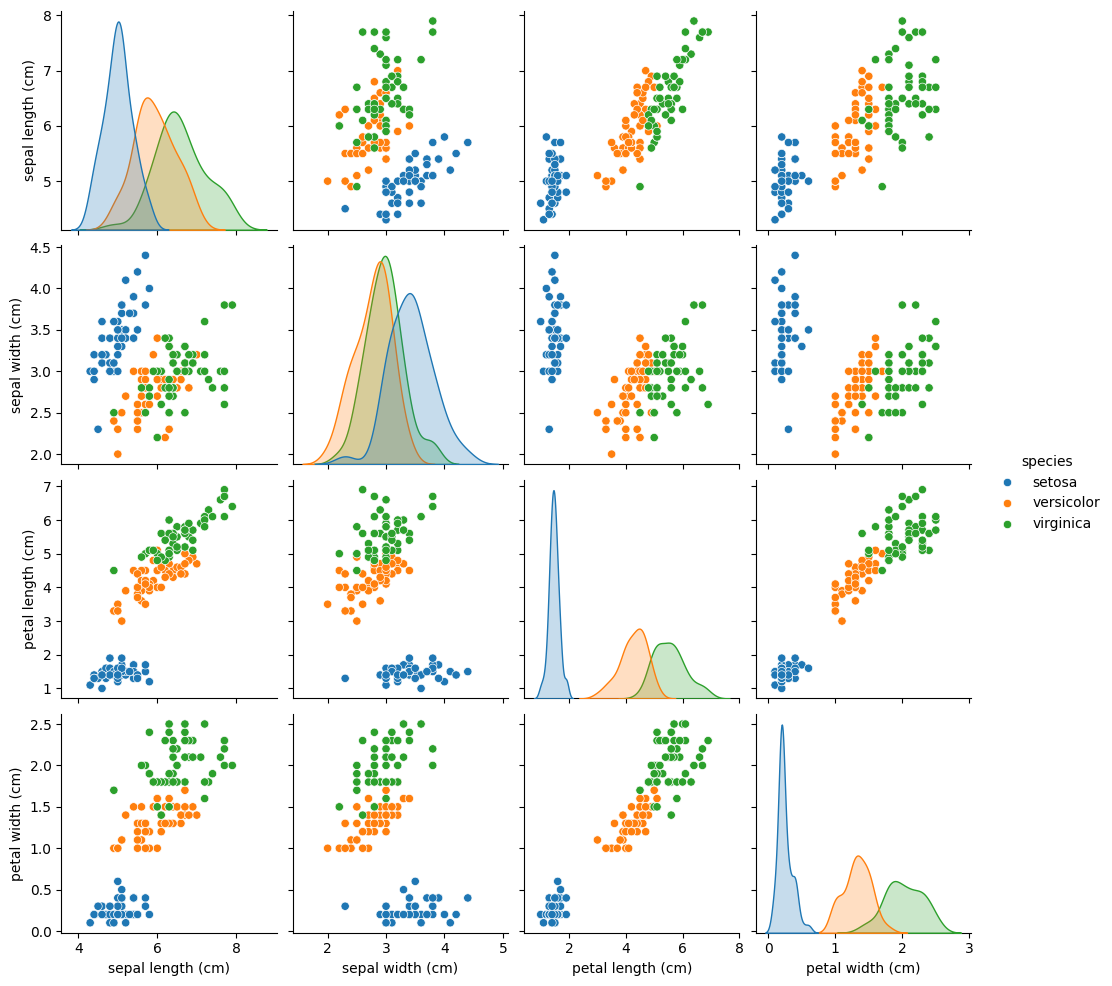

In [ ]:
#Langkah 3 - Visualisasi Data
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

In [ ]:
# Langkah 4 - Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]  # semua kolom kecuali label
y = data.iloc[:, -1]   # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standarisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
#Langkah 5 - Buat Model KNN
from sklearn.neighbors import KNeighborsClassifier
# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)
# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
#Langkah 6 - Evaluasi Model KNN
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



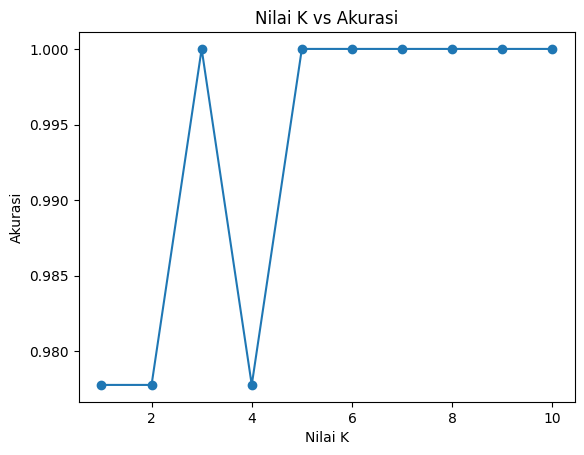

In [ ]:
acc = []
for k in range(1, 11):
	  model = KNeighborsClassifier(n_neighbors=k)
	  model.fit(X_train, y_train)
	  acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()



> Praktikum 2



In [ ]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[126 265]
 [123  89]
 [ 14 259]
 [197  24]
 [109  40]
 [ 34 175]
 [174  21]
 [ 20 175]
 [117 101]
 [ 78  99]
 [ 70 101]
 [131 100]
 [ 92 100]
 [ 91 101]
 [ 99 100]
 [119 100]
 [130 110]
 [ 79 111]
 [100  87]
 [ 95 100]
 [ 91  86]
 [115 120]
 [ 80 114]
 [ 82 192]
 [135 189]
 [173 271]
 [ 36  80]
 [  1  90]
 [ 60  28]
 [140 145]]
[1 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [ ]:
#Langkah 2 - Membuat Data Frame
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,126,265,1
1,123,89,0
2,14,259,0
3,197,24,0
4,109,40,0


In [ ]:
#Langkah 3 - Labeling
# Definisikan nama label
labels = {
	  1 : 'Kelas A',
	  0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,126,265,Kelas A
1,123,89,Kelas B
2,14,259,Kelas B
3,197,24,Kelas B
4,109,40,Kelas B


/tmp/ipykernel_1676/1208472927.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_1676/1208472927.py:13: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


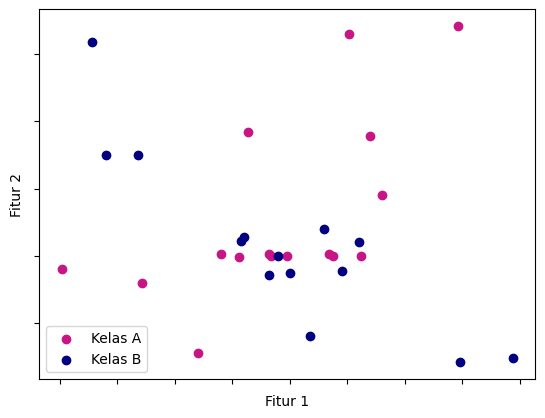

In [ ]:
#Langkah 4 - Visualisasi Data
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
	  'class_a': 'MediumVioletRed',
	  'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

In [ ]:
#Langkah 5 - Model Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy
# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.5714285714285714
Hasil akurasi data test: 0.4444444444444444


In [ ]:
#Langkah 6 - Model Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial
# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.5714285714285714
Hasil akurasi data test (Gaussian): 0.4444444444444444




> Praktikum 3



In [ ]:
#Load Data
import numpy as np
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/Mesin/spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
#Langkah 2a - Drop Kolom
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:,2:], axis=1)

# Cek data
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df = df.iloc[:, :2]
df.columns = ['Labels', 'SMS']

In [ ]:
#Langkah 2b - Inspeksi Data
# Cek Jumlah Data Per Kelas
print(df['Labels'].value_counts())
print('\n')

# Cek Kelengkapan Data
print(df.info())
print('\n')

# Cek Statistik Deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


In [ ]:
#Langkah 2c - Encoding Label
# Data untuk label
new_labels = {
	  'spam': 1,
	  'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
#Langkah 2d - Pisahkan Fitur dengan Label
X = df['SMS'].values
y = df['Labels'].values

In [ ]:
#Langkah 3 - Ekstraksi Fitur
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

In [ ]:
# Cek fitur dari proses CountVectorizer
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


In [ ]:
# Langkah 4 - Training dan Evaluasi Model
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data training
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data training
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229




> Tugas 1

1.
Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

In [ ]:
# Import library
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Membaca dataset
data = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/Mesin/voice.csv')

# Memisahkan fitur dan label
X = data.drop('label', axis=1)
y = data['label']

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Standarisasi data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Membuat model kNN
knn = KNeighborsClassifier(n_neighbors=5)

# Melatih model
knn.fit(X_train, y_train)

# Prediksi
y_pred = knn.predict(X_test)

# Evaluasi
print("Akurasi:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Akurasi: 0.9763406940063092
              precision    recall  f1-score   support

      female       0.99      0.97      0.98       317
        male       0.97      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



2.
Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

In [ ]:
# Menyimpan data sebelum standarisasi
X_train_original = X_train.copy()
X_test_original = X_test.copy()

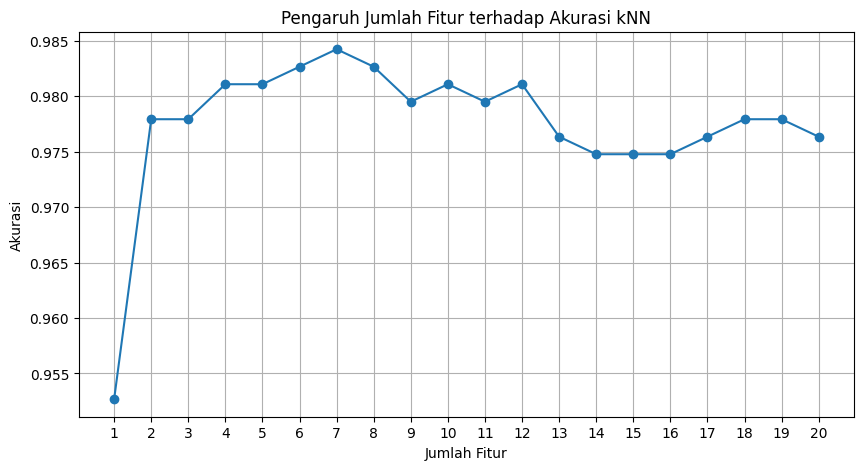

In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
import matplotlib.pyplot as plt

# Percobaan jumlah fitur
hasil_fitur = []

for k in range(1, X.shape[1] + 1):
    selector = SelectKBest(score_func=mutual_info_classif, k=k)

    X_train_selected = selector.fit_transform(
        scaler.fit_transform(X_train_original), y_train)

    X_test_selected = selector.transform(
        scaler.transform(X_test_original))

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train_selected, y_train)

    pred = model.predict(X_test_selected)
    akurasi = accuracy_score(y_test, pred)

    hasil_fitur.append(akurasi)

# Grafik hasil percobaan
plt.figure(figsize=(10, 5))
plt.plot(range(1, X.shape[1] + 1), hasil_fitur, marker='o')
plt.xlabel('Jumlah Fitur')
plt.ylabel('Akurasi')
plt.title('Pengaruh Jumlah Fitur terhadap Akurasi kNN')
plt.xticks(range(1, X.shape[1] + 1))
plt.grid()
plt.show()

In [ ]:
jumlah_fitur_terbaik = hasil_fitur.index(max(hasil_fitur)) + 1

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=jumlah_fitur_terbaik)

selector.fit(X_train_original, y_train)

fitur_terbaik = X.columns[selector.get_support()]

print("Jumlah Fitur Terbaik:", jumlah_fitur_terbaik)
print("Fitur Terbaik:", fitur_terbaik.tolist())
print("Akurasi Terbaik:", max(hasil_fitur))

Jumlah Fitur Terbaik: 7
Fitur Terbaik: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'mode', 'meanfun']
Akurasi Terbaik: 0.9842271293375394


3.
Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

Nilai K Terbaik: 6
Akurasi Terbaik: 0.9858044164037855


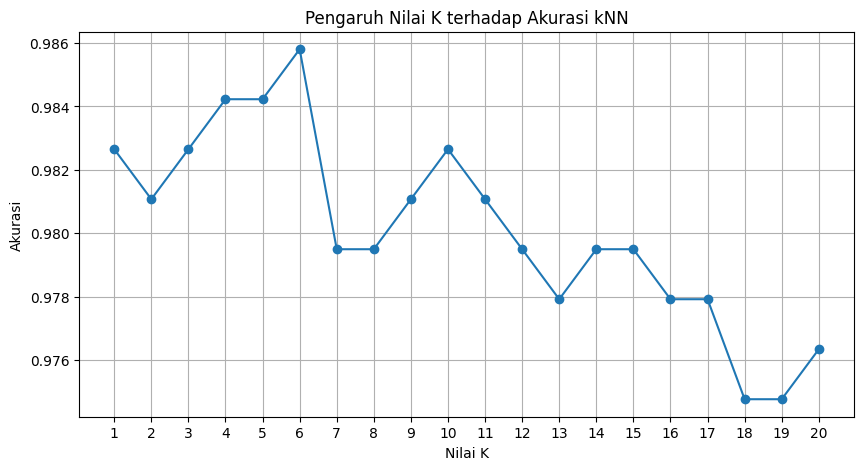

In [ ]:
hasil_k = []
for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)

    X_train_best = SelectKBest(
        mutual_info_classif, k=jumlah_fitur_terbaik
    ).fit(X_train_original, y_train)

    X_train_selected = X_train_best.transform(
        scaler.fit_transform(X_train_original))
    X_test_selected = X_train_best.transform(
        scaler.transform(X_test_original))

    model.fit(X_train_selected, y_train)

    pred = model.predict(X_test_selected)
    hasil_k.append(accuracy_score(y_test, pred))

# Nilai K terbaik
k_terbaik = hasil_k.index(max(hasil_k)) + 1

print("Nilai K Terbaik:", k_terbaik)
print("Akurasi Terbaik:", max(hasil_k))

# Grafik
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), hasil_k, marker='o')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.title('Pengaruh Nilai K terhadap Akurasi kNN')
plt.xticks(range(1, 21))
plt.grid()
plt.show()



> **TUGAS 2**


*   Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,
1. Menggunakan data spam.csv



In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/SEMESTER 5/Mesin/spam.csv', encoding='latin-1')

df = df.iloc[:, :2]
df.columns = ['Labels', 'SMS']

print(df.head())

  Labels                                                SMS
0    ham  Go until jurong point, crazy.. Available only ...
1    ham                      Ok lar... Joking wif u oni...
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...
3    ham  U dun say so early hor... U c already then say...
4    ham  Nah I don't think he goes to usf, he lives aro...


2. Fitur CountVectorizer dengan mengaktifkan stop_words

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X = df['SMS']
y = df['Labels']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# CountVectorizer dengan stop_words
bow = CountVectorizer(stop_words='english')

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

print("Jumlah Fitur:", len(bow.get_feature_names_out()))
print("Dimensi Data:", X_train_bow.shape)

Jumlah Fitur: 7440
Dimensi Data: (4457, 7440)


3.
Evaluasi hasilnya

Akurasi: 0.9838565022421525
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



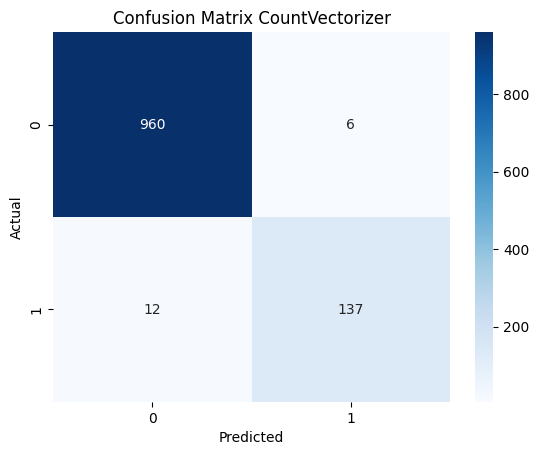

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Membuat model
model_bow = MultinomialNB()

# Training
model_bow.fit(X_train_bow, y_train)

# Prediksi
y_pred_bow = model_bow.predict(X_test_bow)

# Evaluasi
print("Akurasi:", accuracy_score(y_test, y_pred_bow))
print(classification_report(y_test, y_pred_bow))

# Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred_bow),
    annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix CountVectorizer')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

*   Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

2. Fitur TF-IDF dengan mengaktifkan stop_words

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF dengan stop_words
tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Jumlah Fitur:", len(tfidf.get_feature_names_out()))
print("Dimensi Data:", X_train_tfidf.shape)

Jumlah Fitur: 7440
Dimensi Data: (4457, 7440)


3. Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.

Akurasi: 0.968609865470852
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



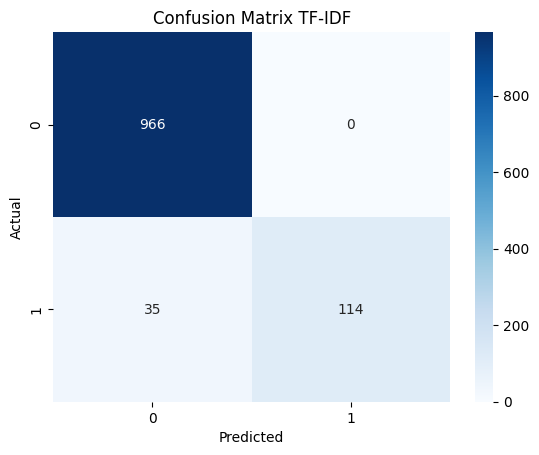

In [ ]:
# Membuat model
model_tfidf = MultinomialNB()

# Training
model_tfidf.fit(X_train_tfidf, y_train)

# Prediksi
y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

# Evaluasi
print("Akurasi:", accuracy_score(y_test, y_pred_tfidf))
print(classification_report(y_test, y_pred_tfidf))

# Confusion Matrix
sns.heatmap(
    confusion_matrix(y_test, y_pred_tfidf),
    annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix TF-IDF')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

4.
Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

            Metode   Akurasi
0  CountVectorizer  0.983857
1           TF-IDF  0.968610


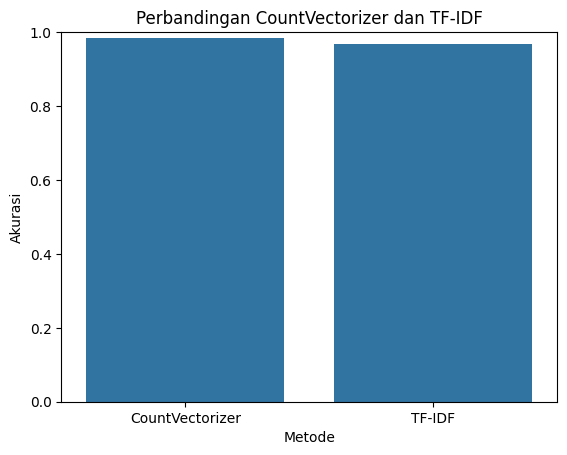

In [ ]:
# Membandingkan akurasi
akurasi_bow = accuracy_score(y_test, y_pred_bow)
akurasi_tfidf = accuracy_score(y_test, y_pred_tfidf)

hasil = pd.DataFrame({
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Akurasi': [akurasi_bow, akurasi_tfidf]})

print(hasil)

# Grafik perbandingan
sns.barplot(data=hasil, x='Metode', y='Akurasi')
plt.title('Perbandingan CountVectorizer dan TF-IDF')
plt.ylabel('Akurasi')
plt.ylim(0, 1)
plt.show()